# 05 - Random Forest

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C
from src.features import get_xy
from src.pipeline import build_model, predict_proba
from src.evaluation import evaluate_and_save, plot_curves, score_at, best_threshold
from sklearn.metrics import average_precision_score

df = pd.read_parquet(C.CLEAN_PATH)
X_train, y_train, _ = get_xy(df, "train")
X_val, y_val, _ = get_xy(df, "val")
X_test, y_test, _ = get_xy(df, "test")
print(X_train.shape, X_val.shape, X_test.shape)

(384548, 13) (81129, 13) (80445, 13)


## Tuning: two settings (kept small so it runs on a free machine)

In [2]:
grid = [{"n_estimators": 80, "max_depth": 8, "min_samples_leaf": 50}, {"n_estimators": 80, "max_depth": 12, "min_samples_leaf": 30}]
results, models = [], []
for params in grid:
    t = time.time()
    m = build_model("random_forest", **params)
    m.fit(X_train, y_train)
    ap = average_precision_score(y_val, predict_proba(m, X_val))
    results.append({**params, "val_pr_auc": round(ap, 4), "seconds": round(time.time() - t, 1)})
    models.append(m)
tuning = pd.DataFrame(results)
display(tuning.sort_values("val_pr_auc", ascending=False))
i = int(tuning["val_pr_auc"].idxmax())
model, best_params = models[i], grid[i]
print("Best settings:", best_params)

,n_estimators,max_depth,min_samples_leaf,val_pr_auc,seconds
0,80,8,50,0.1016,13.0
1,80,12,30,0.0955,16.9


Best settings: {'n_estimators': 80, 'max_depth': 8, 'min_samples_leaf': 50}


## Evaluate on validation and test

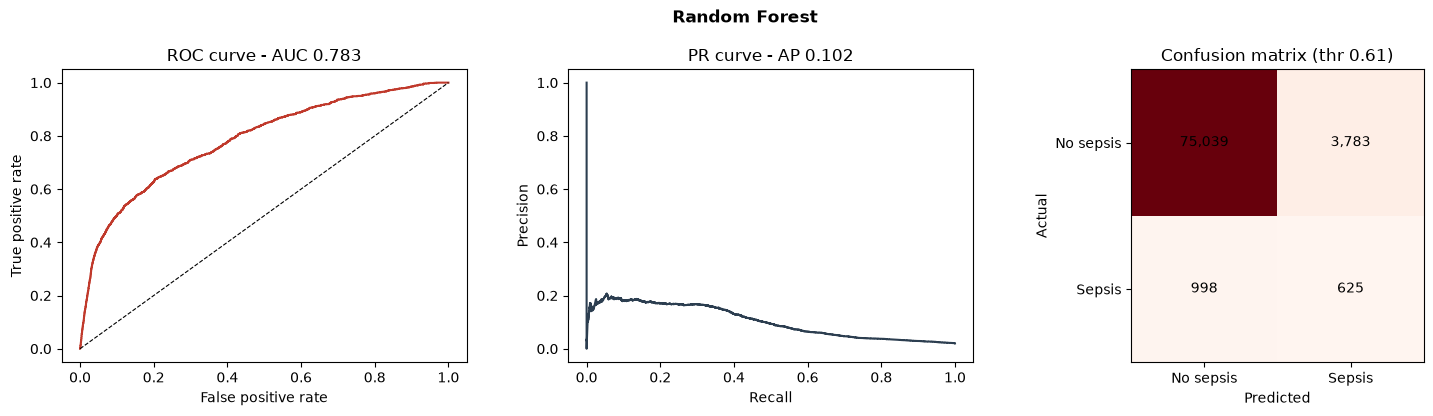

,val,test
roc_auc,0.765,0.783
pr_auc,0.102,0.102
precision,0.143,0.142
recall,0.337,0.385
specificity,0.955,0.952
f1,0.201,0.207
f2,0.266,0.287
balanced_accuracy,0.646,0.669


In [3]:
p_val = predict_proba(model, X_val)
p_test = predict_proba(model, X_test)
res = evaluate_and_save("random_forest", y_val, p_val, y_test, p_test, extra={"params": best_params, "tuning": tuning.to_dict("records")})
plot_curves(y_test, p_test, "Random Forest", res["test"]["threshold"])
pd.DataFrame(res).loc[["roc_auc","pr_auc","precision","recall","specificity","f1","f2","balanced_accuracy"], ["val","test"]].round(3)

## Feature importance

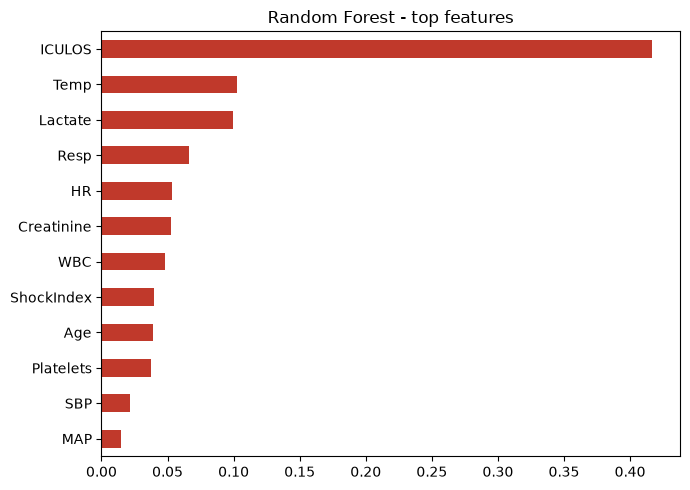

In [4]:
imp = pd.Series(model.named_steps["model"].feature_importances_, index=X_train.columns).sort_values().tail(12)
imp.plot.barh(figsize=(7, 5), color="#c0392b"); plt.title("Random Forest - top features")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "random_forest_importance.png", dpi=130); plt.show()